# 质量度量下的拉格朗日 Hodge–Dirac（LHD）：可运行演示
本 notebook 只用示踪点**位置**（加初始密度），演示整套方法的核心环节：
1. 有限步恒等式（复上链：环量 + 面积变化；位置形式 Kelvin 定理）
2. 物质账本：Sod 激波管的密度、与 DTFE/SPH 的对比、合并穿越块的激波签名
3. 质量度量的网络扩散：质量形式 vs 体积形式 vs SPH
4. 掺混归因：爆炸波圆环的链式张量拉伸与账本压缩
5. 加权动态 Laplacian（取代 T7）：Lamb–Oseen 涡核
6. 断轨：逐轨账本 vs 窗口化账本

DNS 算例（激波–重气泡、激波–等熵涡、Richtmyer–Meshkov、粘性激波–气泡）计算量较大，复现脚本见 `scripts/` 与 README。

In [1]:
import sys, numpy as np, matplotlib.pyplot as plt
sys.path.insert(0, 'lhd'); sys.path.insert(0, 'scripts')
import lhdx as X, cases
from lhdp import tri_F, pq, disp_cochain_tri, kelvin_pos, tri_area
from bcom import ledger, errstats, density_all, sph_diffusion, rel
import netdiff as ND, stretch_est as SE, stream as ST
np.set_printoptions(precision=4, suppress=True)
print('modules loaded')

modules loaded


## 1. 有限步恒等式
对任意三角形、任意一步：中点位移上链的环量 $=2A^n\,\mathrm{Im}\,p$，法向通量 $=A^{n+1}-A^n$；位置形式 Kelvin：$\Gamma^{n+1/2}-\Gamma^{n-1/2}=(d_1g^n)_t$，与步长无关。

In [2]:
rng = np.random.default_rng(0); P0 = rng.uniform(-1, 1, (400, 2)); tri = X.complex_peeled(P0)['tri']
F = np.eye(2) + rng.normal(0, 0.6, (2, 2)); F = F if np.linalg.det(F) > 0.1 else np.eye(2)
P1 = P0 @ F.T + rng.normal(0, 1, 2) + 0.01*rng.normal(size=P0.shape)       # large affine step + non-affine jitter
circ, flux = disp_cochain_tri(P0, P1, tri); Fe, A0 = tri_F(P0, P1, tri); p, q = pq(Fe)
print('max |circ - 2A Im p| / max A :', np.max(np.abs(circ - 2*A0*p.imag))/np.max(np.abs(A0)))
print('max |flux - dA|      / max A :', np.max(np.abs(flux - (tri_area(P1, tri)-A0)))/np.max(np.abs(A0)))
Pm, Pp = P0 + 0.05*rng.normal(size=P0.shape), P0 + 0.05*rng.normal(size=P0.shape)
d, dg, Gp, Gm = kelvin_pos(Pm, P0, Pp, tri)
print('position-form Kelvin residual :', np.max(np.abs(d - dg))/np.max(np.abs(d)))

max |circ - 2A Im p| / max A : 1.272042506315109e-15
max |flux - dA|      / max A : 1.246082455165821e-15
position-form Kelvin residual : 5.438115166451942e-16


## 2. Sod 激波管：只凭位置的物质账本
账本 $\rho_i=\rho_{0,i}e^{-\ln J_i}$，$\ln J$ 为逐点锚定的星面积比之和，跨激波推迟重锚使面积比望远相消。与 DTFE、SPH（同一组质量）比较。

ledger  {'med': 3.774758283725532e-15, 'p95': 0.009650339165268269, 'p99': 0.13512829821590747}
dtfe    {'med': 0.001989226808028155, 'p95': 0.3783616836352856, 'p99': 0.7328710574024335}
sph     {'med': 0.01922236259250082, 'p95': 0.07133440986785829, 'p99': 0.37105315948595524}


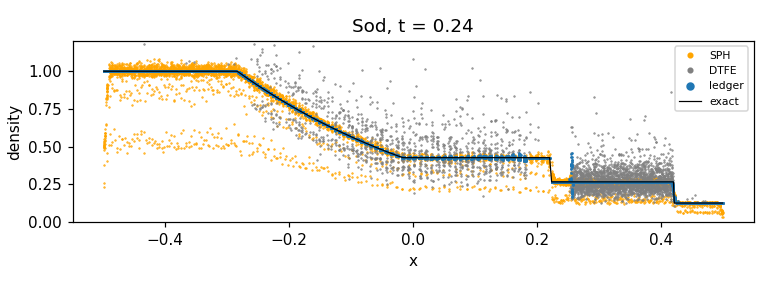

In [3]:
c = cases.case_sod(h=0.004); fr = c['frames']; ref = c['rho'][-1]; mask = c['interior'](fr[0])
lnJ, hot, bad, tau = ledger(fr)
m, D = density_all(fr, c['rho'][0], lnJ, mask)
for k, v in D.items(): print('%-7s' % k, errstats(v, ref, mask))
x = fr[-1][:, 0]; o = np.argsort(x)
plt.figure(figsize=(7, 2.6))
plt.plot(x[o], D['sph'][o], '.', ms=1, color='orange', label='SPH'); plt.plot(x[o], D['dtfe'][o], '.', ms=1, color='gray', label='DTFE')
plt.plot(x[o], D['ledger'][o], '.', ms=1.5, color='C0', label='ledger'); plt.plot(x[o], ref[o], 'k-', lw=0.8, label='exact')
plt.ylim(0, 1.2); plt.xlabel('x'); plt.ylabel('density'); plt.legend(markerscale=6, fontsize=7); plt.title('Sod, t = 0.24'); plt.tight_layout()

blocks: 6384  median |mu_B - tanh(|lnJ_B|/2)| = 1.1102230246251565e-16
pseudo-rotation p95: per-step sum 0.0923 rad -> merged block 0.00566 rad


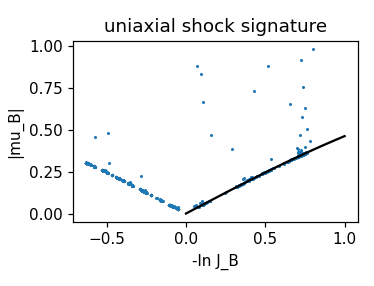

In [4]:
exec(open('scripts/n4_shock_lib.py').read())
sig, pst, pbl = block_signature(fr)
print('blocks:', len(sig), ' median |mu_B - tanh(|lnJ_B|/2)| =', np.median(np.abs(sig[:, 1]-np.tanh(0.5*np.abs(sig[:, 0])))))
print('pseudo-rotation p95: per-step sum %.4f rad -> merged block %.5f rad' % (np.quantile(pst, .95), np.quantile(pbl, .95)))
xx = np.linspace(0, 1, 100); plt.figure(figsize=(3.4, 2.6)); plt.plot(sig[:, 0], sig[:, 1], '.', ms=2); plt.plot(xx, np.tanh(xx/2), 'k-')
plt.xlabel('-ln J_B'); plt.ylabel('|mu_B|'); plt.title('uniaxial shock signature'); plt.tight_layout()

## 3. 质量度量的网络扩散
$M\dot c=-K(t)c$，$M=\mathrm{diag}(m_i)$（质量），$K$ 为以 $\rho\kappa$ 加权的 P1 刚度（$D^2$ 的节点块）。参照：质量坐标下的一维精确扩散。

In [5]:
src = open('scripts/tr_b.py').read()
exec(src.split('# ================= D1')[0].split("R = {'D'")[0]); exec('def lag1d' + src.split('def lag1d')[1].split('def polylen')[0])
kap = 1e-3; c0f = lambda x0: 0.5*(1+np.tanh(x0/0.02))
fine = cases.case_sod(h=2e-4, Ly=2e-4, t0=0.04, t1=0.24, S=401); o2 = np.argsort(fine['x0']); x0f = fine['x0'][o2]
dmu = np.where(x0f > 0, 0.125, 1.0)*2e-4; rhoF = fine['rho'][:, o2]; tF = fine['t']
cond = lambda t: (lambda r: 2*r[1:]**2*r[:-1]**2/(r[1:]**2+r[:-1]**2))(rhoF[min(int(round((t-tF[0])/(tF[1]-tF[0]))), len(tF)-1)])
cref = np.interp(c['x0'], x0f, lag1d(dmu, cond, c0f(x0f), tF, kap))
rho = c['rho'][0][None, :]*np.exp(-lnJ); c0 = c0f(c['x0'])
cm = ND.run(fr, c['dt'], c0, kap, 'mass', m=c['mass'], rho=rho)[fr.shape[0]-1]
cv = ND.run(fr, c['dt'], c0, kap, 'volume', m=c['mass'], rho=rho)[fr.shape[0]-1]
cs = sph_diffusion(fr, c['dt'], c0, kap, c['mass'], rho)
for nm, v in [('network, mass form', cm), ('network, volume form', cv), ('SPH conduction', cs), ('pure advection', c0)]:
    print('%-22s rel L2 error = %.4f' % (nm, rel(v[mask], cref[mask])))

network, mass form     rel L2 error = 0.0017
network, volume form   rel L2 error = 0.0185
SPH conduction         rel L2 error = 0.0088
pure advection         rel L2 error = 0.0743


## 4. 掺混归因：爆炸波圆环
$\ln(|\nabla c|/|\nabla c_0|)=\ln\lambda-\ln J$（Nanson 恒等式）。拉伸 $\lambda=|FT|$ 用链式张量估计，压缩取自账本。精确值：拉伸 $p\ln 4\approx0.578$。

In [6]:
cb = cases.case_blast(h=0.022); frb = cb['frames']; rs = cb['rs']; P0 = frb[0]
lnJb, hotb, badb, _ = ledger(frb)
band = np.where(np.abs(rs-0.5) < 0.6*0.022)[0]; th = np.arctan2(P0[band, 1], P0[band, 0]); t0 = np.c_[-np.sin(th), np.cos(th)]
Fb = SE.chained_F(frb, 0.022, bad=badb, idx=band, keep={frb.shape[0]-1})[frb.shape[0]-1][0]
ll, A = SE.vector_lnlam(Fb, t0)
print('stretch  chained tensor: %.4f   exact: %.4f' % (ll.mean(), np.log(4)/2.4))
print('compression ledger     : %.4f   exact: %.4f' % (-lnJb[-1][band].mean(), -(cb['lnJ_ex'][-1]-cb['lnJ_ex'][0])[band].mean()))

stretch  chained tensor: 0.5765   exact: 0.5776
compression ledger     : 0.6366   exact: 0.6375


## 5. 加权动态 Laplacian（取代 T7 的 Ulam 矩阵）
$\bar K v=\lambda Mv$，$\bar K$ 为各时刻 P1 刚度的平均（Froyland–Junge 2018 的离散），$M$ 为账本质量（Froyland–Kwok 2020 的权重）。

eigenvalues: [0.     0.1158 0.1787 0.2622]
best Jaccard with a vortex core: 0.45  (Ulam transfer operator: 0.11)


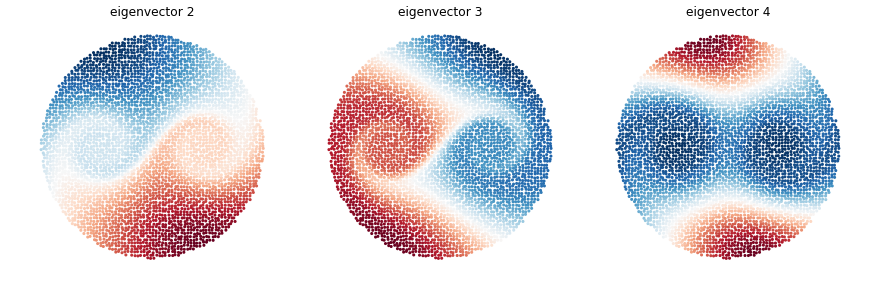

In [7]:
exec(open('scripts/g5_dynlap.py').read().split('out = {}')[0])
cl = cases.case_lo(a=1.0, Rd=6.5, N=4000); frl = cl['frames']; ml = X.star_area(frl[0])/3.0
vals, V = dynlap(frl, ml); P0l = frl[0]
cores = [np.hypot(*(P0l-np.array(cc)).T) < 1.5 for cc in cl['centres']]
best = max(jacc(s*V[:, j] >= np.quantile(s*V[:, j], .9), cores[0] | cores[1]) for j in range(1, 4) for s in (1, -1))
best1 = max(max(jacc(s*V[:, j] >= np.quantile(s*V[:, j], .9), cc) for cc in cores) for j in range(1, 4) for s in (1, -1))
print('eigenvalues:', vals); print('best Jaccard with a vortex core: %.2f  (Ulam transfer operator: 0.11)' % best1)
fig, ax = plt.subplots(1, 3, figsize=(8, 2.6))
for j in range(3): ax[j].scatter(P0l[:, 0], P0l[:, 1], c=V[:, j+1], s=1, cmap='RdBu_r'); ax[j].set_aspect('equal'); ax[j].set_title('eigenvector %d' % (j+2), fontsize=8); ax[j].axis('off')
plt.tight_layout()

## 6. 断轨：逐轨账本
每条轨迹保持自己的锚定星；邻居消失时缩减环；环在激波中断开时在锚定帧用幸存轨迹重建环；新轨迹延迟到离开激波后再标定。对比旧的 5 帧窗口化账本。

In [8]:
S_, N_ = fr.shape[:2]; cross = np.full(N_, -1); cross[c['ev_pidx']] = c['ev_step']; rg = np.random.default_rng(7)
forced = np.zeros((N_, S_), bool); sel = (cross >= 0) & (rg.random(N_) < 0.3); forced[np.where(sel)[0], cross[sel]] = True
for name, p, fo in [('random breaks 3%/frame', 0.03, None), ('30% break while crossing the shock', 0.01, forced)]:
    P, own, st, en = ST.tracks_from_particles(fr, p, seed=3, forced=fo); rinit = np.where(st == 0, c['rho'][0][own], np.nan)
    rs_, _ = ST.ledger_stream(P, rinit); rw = ST.ledger_windowed(P, rinit)
    fin = ~np.isnan(P[-1, :, 0]); tr = c['rho'][-1][own]; mk = mask[own]
    for nm, r in [('streaming', rs_), ('windowed', rw)]:
        ok = fin & np.isfinite(r[-1]); e = errstats(r[-1][ok], tr[ok], mk[ok])
        print('%-36s %-10s coverage %.2f  median %.2e  p95 %.4f' % (name, nm, ok.sum()/fin.sum(), e['med'], e['p95']))

random breaks 3%/frame               streaming  coverage 1.00  median 8.94e-15  p95 0.0163
random breaks 3%/frame               windowed   coverage 0.86  median 9.44e-15  p95 0.0490
30% break while crossing the shock   streaming  coverage 1.00  median 7.55e-15  p95 0.0190
30% break while crossing the shock   windowed   coverage 0.93  median 8.10e-15  p95 0.0562


## 7. 复现 DNS 算例
| 内容 | 脚本 |
|---|---|
| 激波–重气泡 DNS（无粘，三档网格） | `scripts/run_sb_any.py 0.01/0.005/0.0025` |
| 粘性激波–重气泡（$\mu=5\times10^{-4}$） | `scripts/run_sb_visc.py 0.01/0.005/0.0035` |
| 激波–等熵涡 DNS | `scripts/run_sv_fine.py 0.005`（或 `lhd/sv_case.py`） |
| 单模 Richtmyer–Meshkov | `scripts/run_rm.py 0.005`，分析 `scripts/r1_rm.py` |
| DNS 加密分析 | `scripts/dns_ref.py sb / sv / sbv` |
| 环量与 Samtaney–Zabusky 模型 | `scripts/g6_sz.py` |
| 断轨全部情形 | `scripts/s1_exp.py sod / sv / blast` |

全部数值结果见 `results/*.json`。